In [1]:
%load_ext autoreload
%autoreload 2

import anndata as ad
adata = ad.read_h5ad("./data/larry/larry_processed.h5ad")
adata

AnnData object with n_obs × n_vars = 49302 × 2000
    obs: 'Library', 'Cell barcode', 'time_info', 'Starting population', 'state_info', 'Well', 'SPRING-x', 'SPRING-y', 'initial_size_unspliced', 'initial_size_spliced', 'initial_size', 'n_counts', 'velocity_self_transition'
    var: 'Accession', 'Chromosome', 'End', 'Start', 'Strand', 'gene_count_corr', 'means', 'dispersions', 'dispersions_norm', 'highly_variable', 'velocity_gamma', 'velocity_qreg_ratio', 'velocity_r2', 'velocity_genes'
    uns: 'data_des', 'log1p', 'neighbors', 'pca', 'state_info_colors', 'velocity_graph', 'velocity_graph_neg', 'velocity_params'
    obsm: 'X_clone', 'X_emb', 'X_pca', 'X_spring', 'velocity_spring'
    varm: 'PCs'
    layers: 'Ms', 'Mu', 'ambiguous', 'matrix', 'spliced', 'unspliced', 'variance_velocity', 'velocity'
    obsp: 'connectivities', 'distances'

In [2]:
import joblib
from scripts.VectorFieldEmbedder import VectorFieldEmbedder
from scripts.plotting import *

# Load the object back
emb = joblib.load("./data/larry/larry_embedder.pkl")
emb.gene_names = adata.var_names

print("Loaded object:", type(emb))

Loaded object: <class 'scripts.VectorFieldEmbedder.VectorFieldEmbedder'>


In [3]:
from scripts.VectorFieldGeometry import FixedPointAnalyzer

# ---------------------------------------------------
# Run fixed point analysis
# ---------------------------------------------------
fpa = FixedPointAnalyzer(emb)

fp_info = fpa.identify_fixed_points(
    grid_size=60,
    speed_smooth_sigma=2.3,
    radius_percent=0.1,
)

print(f"Found {len(fp_info)} fixed points")

for i, info in enumerate(fp_info):
    print(f"\nFixed point {i}")
    print("  position:", info["position"])
    print("  type:", info["type"])

Found 2 fixed points

Fixed point 0
  position: [3.08698882 3.95093617]
  type: Unstable node (source)

Fixed point 1
  position: [7.70104703 4.54136332]
  type: Spiral out (unstable)


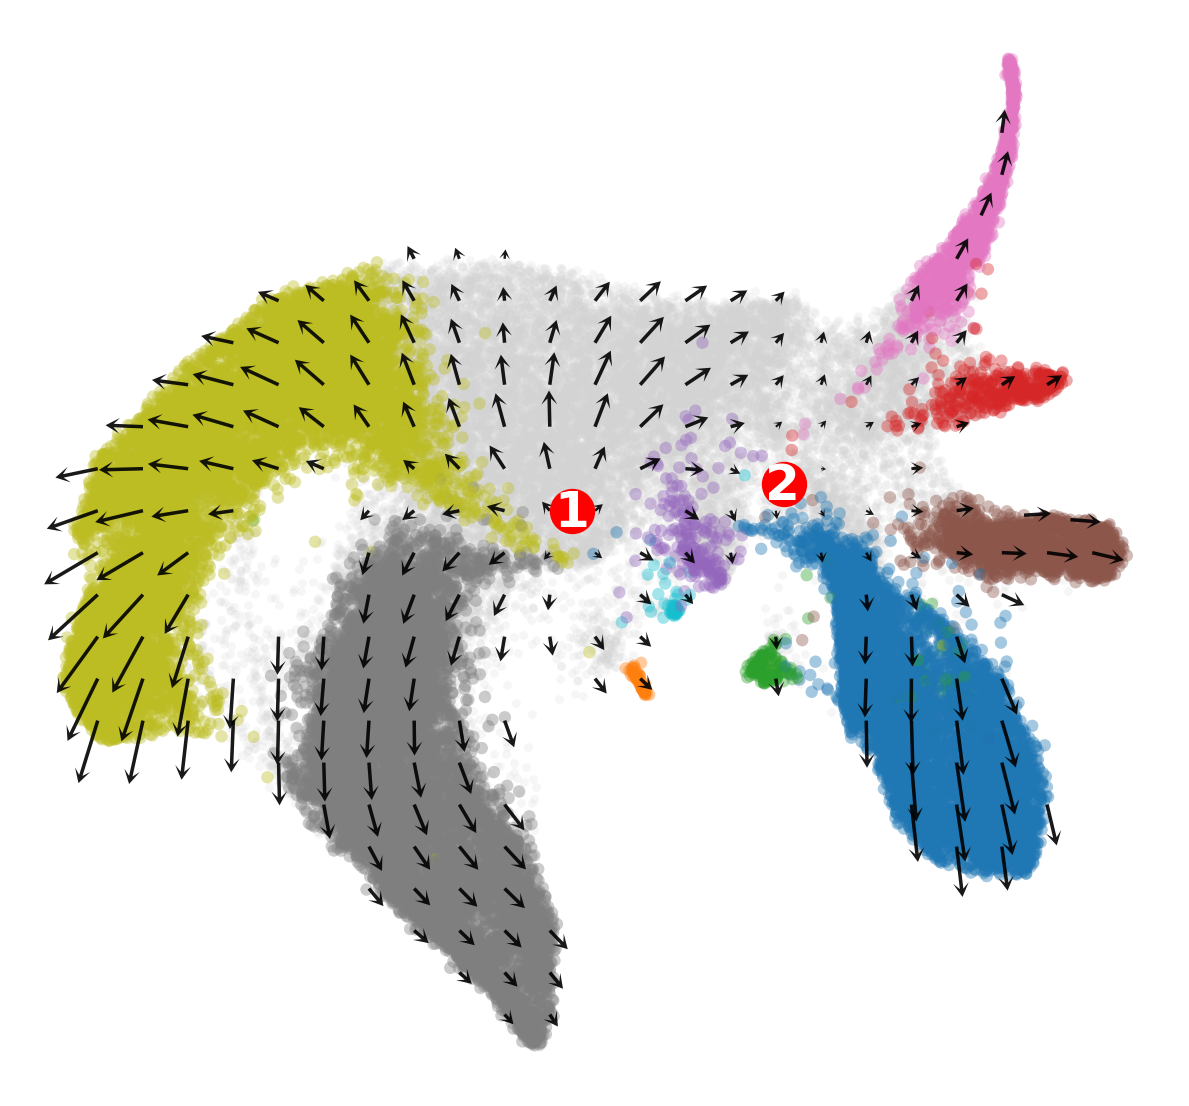

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from sklearn.neighbors import NearestNeighbors
from scripts.plotting import compute_velocity_on_grid
from matplotlib.lines import Line2D

# --------------------------------------------------------------------------
# FIXED POINTS (DEFINE ONCE, USE EVERYWHERE)
# --------------------------------------------------------------------------
fp1 = fp_info[0]["position"]   # Fixed point 1 (source)
fp2 = fp_info[1]["position"]   # Fixed point 2 (saddle)

# --------------------------------------------------------------------------
# Helpers
# --------------------------------------------------------------------------
def points_inside_mask(X_emb, seeds, k=8, radius_scale=1.2):
    nn = NearestNeighbors(n_neighbors=k).fit(X_emb)
    r = np.median(nn.kneighbors(X_emb, n_neighbors=k)[0][:, -1]) * radius_scale
    neigh_idx = nn.radius_neighbors(seeds, radius=r, return_distance=False)
    return np.array([len(ix) > 0 for ix in neigh_idx])


def add_manual_arrows(ax, coords, X_emb, V_pred):
    nn = NearestNeighbors(n_neighbors=1).fit(X_emb)
    _, idx = nn.kneighbors(coords)
    idx = idx.ravel()

    ax.quiver(
        X_emb[idx, 0], X_emb[idx, 1],
        V_pred[idx, 0], V_pred[idx, 1],
        angles="xy", scale_units="xy", scale=3,
        width=0.003,
        headwidth=4.5, headlength=4.0, headaxislength=2.3,
        minlength=0.2,
        color="k", alpha=0.9
    )


# --------------------------------------------------------------------------
# 1) Embedding & labels
# --------------------------------------------------------------------------
X_emb = emb.X_emb
labels = np.asarray(adata.obs["state_info"].values)

# --------------------------------------------------------------------------
# 2) Colors
# --------------------------------------------------------------------------
uniq = np.unique(labels)
other = [lab for lab in uniq if lab != "Undifferentiated"]
cmap = plt.get_cmap("tab10", len(other))
colmap = {lab: mcolors.to_hex(cmap(i)) for i, lab in enumerate(other)}
colmap["Undifferentiated"] = "#d3d3d3"
cell_colors = np.array([colmap[lab] for lab in labels])

# --------------------------------------------------------------------------
# 3) Velocity grid
# --------------------------------------------------------------------------
Xg, keep_mass, _ = compute_velocity_on_grid(
    X_emb, grid_size=25, min_mass=0.01
)
keep_inside = points_inside_mask(X_emb, Xg)
Xg = Xg[keep_inside]
Vg = emb.tps_vf.predict(Xg)

# --------------------------------------------------------------------------
# 4) Plot
# --------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 12))

# Background: Undifferentiated
if "Undifferentiated" in uniq:
    m = labels == "Undifferentiated"
    ax.scatter(
        X_emb[m, 0], X_emb[m, 1],
        c="#d3d3d3", s=40, alpha=0.2, linewidths=0
    )

# Foreground cells
m = labels != "Undifferentiated"
ax.scatter(
    X_emb[m, 0], X_emb[m, 1],
    c=cell_colors[m], s=80, alpha=0.4, linewidths=0
)

# Velocity field
ax.quiver(
    Xg[:, 0], Xg[:, 1],
    Vg[:, 0], Vg[:, 1],
    angles="xy", scale_units="xy", scale=3,
    width=0.003,
    headwidth=4.5, headlength=4.0, headaxislength=2.3,
    minlength=0.2,
    color="k", alpha=0.9
)

# --------------------------------------------------------------------------
# 5) Fixed points (explicit, no indices)
# --------------------------------------------------------------------------
dx, dy = -0.02, -0.03

# Fixed point 1
ax.scatter(fp1[0], fp1[1], color="red", s=1000, zorder=4)
ax.text(
    fp1[0] + dx, fp1[1] + dy, "1",
    color="white", fontsize=36, weight="bold",
    ha="center", va="center", zorder=5
)

# Fixed point 2
ax.scatter(fp2[0], fp2[1], color="red", s=1000, zorder=4)
ax.text(
    fp2[0] + dx, fp2[1] + dy, "2",
    color="white", fontsize=36, weight="bold",
    ha="center", va="center", zorder=5
)

# --------------------------------------------------------------------------
# 6) Manual arrows (optional patches)
# --------------------------------------------------------------------------
patch_coords = [
    [12.0, 10.4],
    [14.0, 4.0],
    [13.0, 4.0],
]

V_cells = emb.tps_vf.predict(X_emb)
add_manual_arrows(ax, patch_coords, X_emb, V_cells)

# --------------------------------------------------------------------------
# 7) Formatting
# --------------------------------------------------------------------------
ax.set_aspect("equal")
ax.set_xticks([]); ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.show()

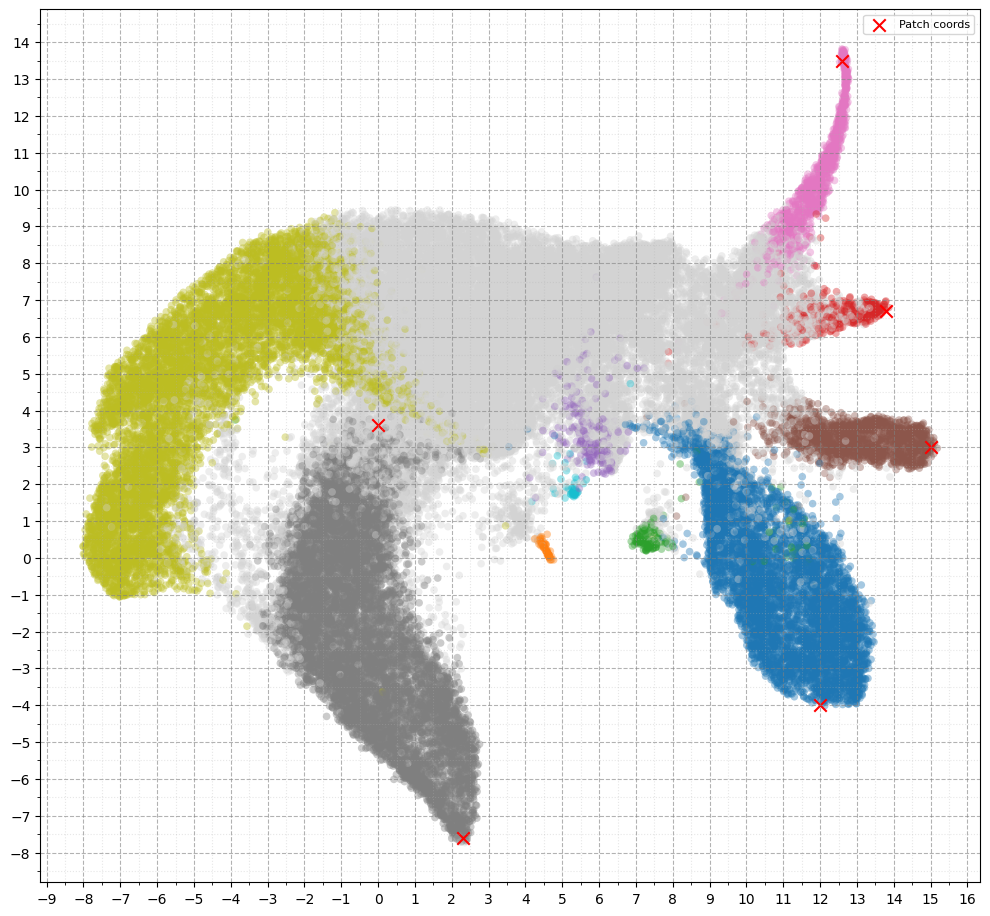

In [5]:
from matplotlib.ticker import MultipleLocator

uniq = np.unique(labels)
other = [lab for lab in uniq if lab != "Undifferentiated"]
cmap = plt.get_cmap("tab10", len(other))
colmap = {lab: mcolors.to_hex(cmap(i)) for i, lab in enumerate(other)}
colmap["Undifferentiated"] = "#d3d3d3"
cell_colors = np.array([colmap[lab] for lab in labels])

# Example patch coordinates (replace with your list)
patch_coords = [
    [12.6, 13.5],
    [13.8, 6.7],
    [15., 3.],
    [12., -4],
    [0., 3.6],
    [2.3,-7.6]
]
X_emb = emb.X_emb
fig, ax = plt.subplots(figsize=(10, 10))

# Scatter all cells
ax.scatter(
    X_emb[:, 0], X_emb[:, 1],
    c=cell_colors, s=30, alpha=0.4, linewidths=0
)

# Overlay patch coordinates
patch_coords = np.array(patch_coords)
ax.scatter(
    patch_coords[:, 0], patch_coords[:, 1],
    c="red", s=80, marker="x", label="Patch coords"
)

# Equal aspect
ax.set_aspect("equal")

# Dense grid
ax.grid(True, linestyle="--", alpha=0.6, color="grey")
ax.xaxis.set_major_locator(MultipleLocator(1))   # grid every 1 unit
ax.yaxis.set_major_locator(MultipleLocator(1))   # grid every 1 unit
ax.minorticks_on()                               # finer ticks
ax.xaxis.set_minor_locator(MultipleLocator(0.5))
ax.yaxis.set_minor_locator(MultipleLocator(0.5))
ax.grid(which="minor", linestyle=":", alpha=0.3)

# Legend
ax.legend(fontsize=8, loc="upper right")

plt.tight_layout()
plt.show()

In [6]:
from scripts.LAP import *

# ------------------------------------------------------------
# Endpoints from fp2 (existing)
# ------------------------------------------------------------
coords = np.array([
    [12.6, 13.5],
    [13.8, 6.7],
    [15., 3.],
    [12., -4]
])

lap = LagrangianPathOptimizer(
    vf=emb.tps_vf.predict,
    jacobian=emb.tps_vf.compute_jacobians,
    D=1.0,
    lam=1e-4
)

root = fp2
results = []

# ------------------------------------------------------------
# fp2 → terminal paths (unchanged)
# ------------------------------------------------------------
for i, end in enumerate(coords, start=1):
    print(f"\n=== Path {i}: {root} → {end} ===")
    res = lap.fit_path(
        X=emb.X_emb,
        V=emb.V_emb,
        start=root,
        end=end,
        subsample_n=4000,
        n_segments=100,
        lr=5e-3,
        iters=300,
        plot=True,
        color=cell_colors
    )
    results.append(res)

# ------------------------------------------------------------
# ADDITION: fp1 → fp2 path
# ------------------------------------------------------------
print(f"\n=== Path fp1 → fp2 ===")
res_fp1_fp2 = lap.fit_path(
    X=emb.X_emb,
    V=emb.V_emb,
    start=fp1,
    end=fp2,
    subsample_n=4000,
    n_segments=100,
    lr=5e-3,
    iters=300,
    plot=True,              # keep visualization consistent
    color=cell_colors
)

results.append(res_fp1_fp2)

# ------------------------------------------------------------
# Collect refined paths (now includes fp1 → fp2)
# ------------------------------------------------------------
refined_paths = [r["path_refined"] for r in results]


=== Path 1: [7.70104703 4.54136332] → [12.6 13.5] ===
[LAP] iter=000, S=43.679475
[LAP] iter=050, S=43.033267
[LAP] iter=100, S=42.886375
[LAP] iter=150, S=42.790804
[LAP] iter=200, S=42.716843
[LAP] iter=250, S=42.655646
[LAP] iter=299, S=42.604542

=== Path 2: [7.70104703 4.54136332] → [13.8  6.7] ===
[LAP] iter=000, S=17.230465
[LAP] iter=050, S=16.957144
[LAP] iter=100, S=16.914048
[LAP] iter=150, S=16.893915
[LAP] iter=200, S=16.880099
[LAP] iter=250, S=16.868802
[LAP] iter=299, S=16.859053

=== Path 3: [7.70104703 4.54136332] → [15.  3.] ===
[LAP] iter=000, S=21.166485
[LAP] iter=050, S=21.037031
[LAP] iter=100, S=20.976315
[LAP] iter=150, S=20.926317
[LAP] iter=200, S=20.883129
[LAP] iter=250, S=20.845186
[LAP] iter=299, S=20.812170

=== Path 4: [7.70104703 4.54136332] → [12. -4.] ===
[LAP] iter=000, S=29.826990
[LAP] iter=050, S=29.422021
[LAP] iter=100, S=29.290684
[LAP] iter=150, S=29.205972
[LAP] iter=200, S=29.147351
[LAP] iter=250, S=29.105544
[LAP] iter=299, S=29.075558


In [7]:
from scripts.plotting import *
from scripts.FieldReconstructionEvaluator import *

emb.fit_gene_level_splines(dof_gene=50, dof_vf_gene=50)
evaluator = FieldReconstructionEvaluator(emb)
res = evaluator.evaluate_gene_fit()

[TPS-Gene] Fitting expression spline on 4000 cells …
[TPS-Gene] Mapping velocities …
[TPS-Gene] Fitting velocity spline on 4000 cells …
[TPS-Gene] Done. Saved X_gene (49302, 2000), V_gene (49302, 2000)
[Init] Computing Jacobian and metric of the expression manifold...
[Init] Loaded 49302 cells → Jacobian (49302, 2000, 2), metric (49302, 2, 2), X_gene (49302, 2000), V_gene (49302, 2000)
[Eval] Global: expr=0.0976, vel=-0.1102
[Eval] Per-gene metrics computed for 2000 genes


[Init] Computing Jacobians and pullback metrics ...
[Init] Done in 55.56s → Jacobian (49302, 2000, 2), metric (49302, 2, 2)
[Neighbor] Found 1802 cells within 0.447 radius.
[Init] Computing Jacobian and metric of the expression manifold...
[Init] Loaded 1802 cells → Jacobian (1802, 2000, 2), metric (1802, 2, 2), X_gene (1802, 2000), V_gene (1802, 2000)
[Eval] Global: expr=0.0900, vel=-0.1673
[Eval] Per-gene metrics computed for 2000 genes
[Eval] Selected 1967 genes (expr > None, vel > None)


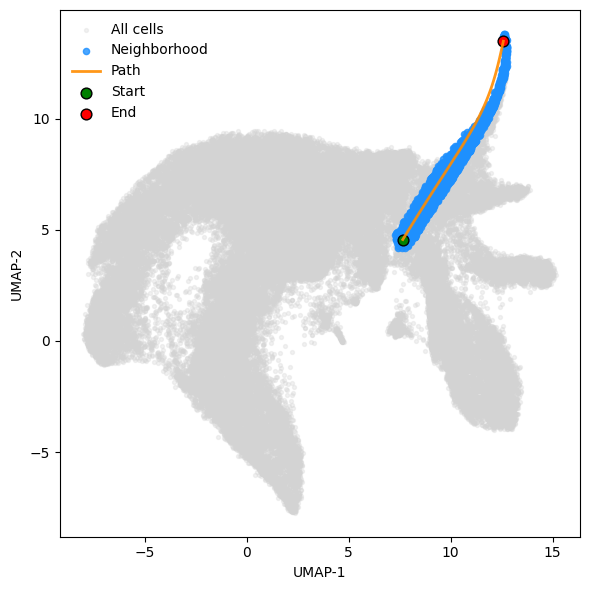

[Neighbor] Found 1168 cells within 0.447 radius.
[Init] Computing Jacobian and metric of the expression manifold...
[Init] Loaded 1168 cells → Jacobian (1168, 2000, 2), metric (1168, 2, 2), X_gene (1168, 2000), V_gene (1168, 2000)
[Eval] Global: expr=0.0270, vel=-0.1994
[Eval] Per-gene metrics computed for 2000 genes
[Eval] Selected 1939 genes (expr > None, vel > None)


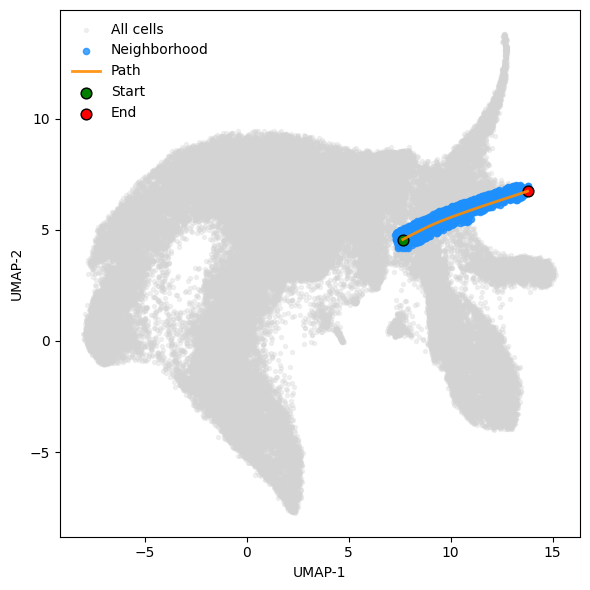

[Neighbor] Found 1307 cells within 0.447 radius.
[Init] Computing Jacobian and metric of the expression manifold...
[Init] Loaded 1307 cells → Jacobian (1307, 2000, 2), metric (1307, 2, 2), X_gene (1307, 2000), V_gene (1307, 2000)
[Eval] Global: expr=0.0450, vel=-0.2480
[Eval] Per-gene metrics computed for 2000 genes
[Eval] Selected 1965 genes (expr > None, vel > None)


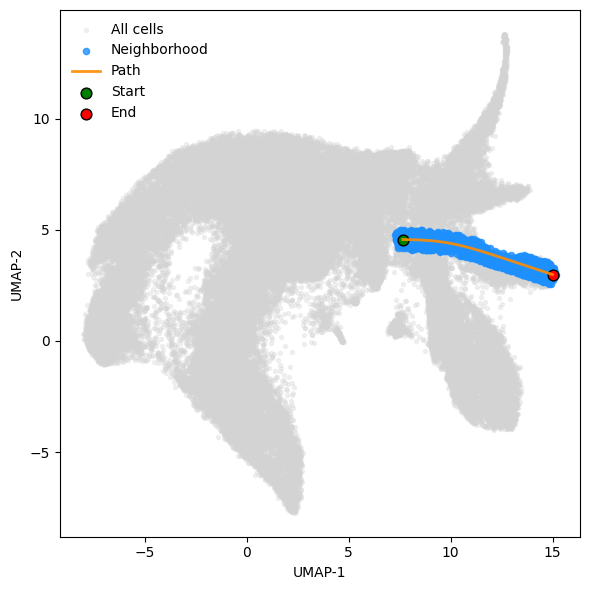

[Neighbor] Found 2467 cells within 0.447 radius.
[Init] Computing Jacobian and metric of the expression manifold...
[Init] Loaded 2467 cells → Jacobian (2467, 2000, 2), metric (2467, 2, 2), X_gene (2467, 2000), V_gene (2467, 2000)
[Eval] Global: expr=0.0214, vel=-0.2284
[Eval] Per-gene metrics computed for 2000 genes
[Eval] Selected 1968 genes (expr > None, vel > None)


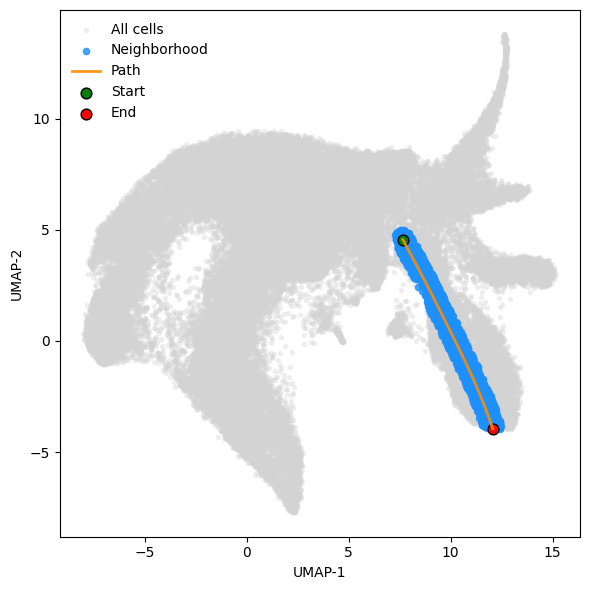

[Neighbor] Found 1105 cells within 0.447 radius.
[Init] Computing Jacobian and metric of the expression manifold...
[Init] Loaded 1105 cells → Jacobian (1105, 2000, 2), metric (1105, 2, 2), X_gene (1105, 2000), V_gene (1105, 2000)
[Eval] Global: expr=0.0041, vel=-0.1120
[Eval] Per-gene metrics computed for 2000 genes
[Eval] Selected 1938 genes (expr > None, vel > None)


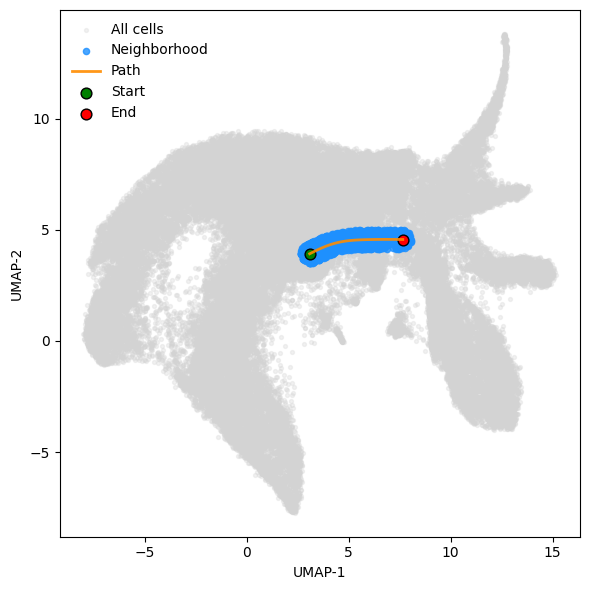

In [10]:
from scripts.GradientAnalyzer import GradientAnalyzer

analyzer = GradientAnalyzer(emb, verbose=True)

for path in refined_paths:
    res = analyzer.evaluate_path_reconstruction(
        path,
        epsilon=0.02,
        threshold_expression=None,
        threshold_velocity=None
    )

    if res is not None:
        neigh_idx = res["neighbor_indices"]
        X = analyzer.emb.X_emb

        plt.figure(figsize=(6, 6))
        plt.scatter(X[:, 0], X[:, 1], c="lightgray", s=8, alpha=0.3, label="All cells")
        plt.scatter(X[neigh_idx, 0], X[neigh_idx, 1],
                    c="dodgerblue", s=20, alpha=0.8, label="Neighborhood")
        plt.plot(path[:, 0], path[:, 1],
                 c="darkorange", lw=2, alpha=0.9, label="Path")

        plt.scatter(path[0, 0], path[0, 1], c="green", s=60, edgecolor="black", label="Start")
        plt.scatter(path[-1, 0], path[-1, 1], c="red", s=60, edgecolor="black", label="End")

        plt.xlabel("UMAP-1")
        plt.ylabel("UMAP-2")
        plt.legend(frameon=False)
        plt.tight_layout()
        plt.show()
    else:
        print("No neighbors found.")

[Saved] ./figures/larry/fp2_branch_paths.pdf


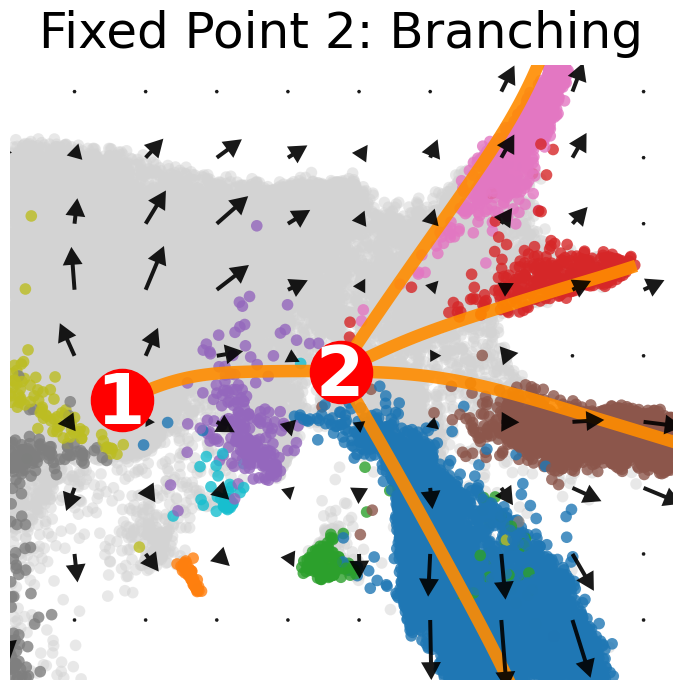

(<Figure size 800x700 with 1 Axes>,
 <Axes: title={'center': 'Fixed Point 2: Branching'}>)

In [16]:
def plot_fixed_point_panel_with_paths(
    fp_idx, fp, X_2d, tps_vf, adata,
    refined_paths,
    epsilon=0.20,
    nx=20, ny=20,
    stream_density=0.7,
    arrowsize=1.5,
    line_scale=2.5,
    savepath=None,
    title=None,
    path_color="red",
    path_alpha=0.8,
    path_style="--"
):
    emb_range = np.ptp(X_2d, axis=0)
    x0, y0 = map(float, fp)
    eps_x = epsilon * emb_range[0]
    eps_y = epsilon * emb_range[1]
    xlim = (x0 - eps_x, x0 + eps_x)
    ylim = (y0 - eps_y, y0 + eps_y)

    # --- Subset cells ---
    mask = (
        (X_2d[:, 0] >= xlim[0]) & (X_2d[:, 0] <= xlim[1]) &
        (X_2d[:, 1] >= ylim[0]) & (X_2d[:, 1] <= ylim[1])
    )
    X_sub = X_2d[mask]
    if X_sub.size == 0:
        print(f"[⚠️] No points near FP{fp_idx} ({x0:.2f}, {y0:.2f}). Skipping.")
        return None

    # --- Cell coloring ---
    labels = np.asarray(adata.obs["state_info"].values)
    uniq = np.unique(labels)
    other = [lab for lab in uniq if lab != "Undifferentiated"]
    cmap = plt.get_cmap("tab10", len(other))
    colmap = {lab: mcolors.to_hex(cmap(i)) for i, lab in enumerate(other)}
    colmap["Undifferentiated"] = "#d3d3d3"

    labels_sub = labels[mask]
    colors_sub = np.array([colmap[lab] for lab in labels_sub])

    undiff_mask = labels_sub == "Undifferentiated"
    diff_mask = ~undiff_mask

    # --- Velocity grid ---
    Xg, keep, Vg, meshes = compute_velocity_on_grid(
        X_sub,
        tps_vf=tps_vf,
        grid_size=nx,
        grid_density=1.0,
        min_mass=0.01,
        return_mesh=True
    )

    xx, yy = meshes
    ny_, nx_ = yy.shape[0], xx.shape[1]
    gx = np.linspace(xx[0, 0], xx[0, -1], nx_, dtype=float)
    gy = np.linspace(yy[0, 0], yy[-1, 0], ny_, dtype=float)
    Vx = np.full((ny_, nx_), np.nan)
    Vy = np.full((ny_, nx_), np.nan)
    dx = (gx[-1] - gx[0]) / (nx_ - 1)
    dy = (gy[-1] - gy[0]) / (ny_ - 1)
    j_idx = np.clip(np.rint((Xg[:, 0] - gx[0]) / dx).astype(int), 0, nx_ - 1)
    i_idx = np.clip(np.rint((Xg[:, 1] - gy[0]) / dy).astype(int), 0, ny_ - 1)
    Vx[i_idx, j_idx] = Vg[:, 0]
    Vy[i_idx, j_idx] = Vg[:, 1]

    # --- Plot ---
    fig, ax = plt.subplots(figsize=(8, 7), facecolor="white")

    # Background (undiff)
    if np.any(undiff_mask):
        ax.scatter(
            X_sub[undiff_mask, 0], X_sub[undiff_mask, 1],
            color="#d3d3d3", s=70, alpha=0.5, edgecolors="none", zorder=1
        )

    # Foreground (diff)
    if np.any(diff_mask):
        ax.scatter(
            X_sub[diff_mask, 0], X_sub[diff_mask, 1],
            color=colors_sub[diff_mask], s=70, alpha=0.8, edgecolors="none", zorder=2
        )

    # --- Dashed LAP paths ---
    for path in refined_paths:
        ax.plot(path[:, 0], path[:, 1],
                path_style, lw=9, color=path_color, alpha=path_alpha, zorder=2.5)

    # --- Vector arrows ---
    skip = (slice(None, None, 2), slice(None, None, 2))
    ax.quiver(
        xx[skip], yy[skip],
        np.nan_to_num(Vx[skip]), np.nan_to_num(Vy[skip]),
        angles="xy", scale_units="xy", scale=2.5,
        width=0.006, headwidth=5.0, headlength=4.5,
        color="k", alpha=0.9, zorder=3
    )
    dx = -0.03
    dy = -0.08
    # --- Fixed point 2 marker (existing) ---
    ax.scatter(x0, y0, color="red", s=2000, zorder=4)
    ax.text(x0+dx, y0+dy, str(fp_idx),
            color="white", fontsize=50, weight="bold",
            ha="center", va="center", zorder=5)

    # =========================================================
    # 🚨 DUCT-TAPED ADDITION: annotate Fixed Point 1
    # =========================================================
    x1, y1 = map(float, fp1)

    ax.scatter(x1, y1, color="red", s=2000, zorder=4)
    ax.text(
        x1+dx, y1+dy,
        "1",
        color="white",
        fontsize=50,
        weight="bold",
        ha="center",
        va="center",
        zorder=5
    )
    # =========================================================

    # --- Aesthetics ---
    ax.set_xlim(xlim); ax.set_ylim(ylim)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    ax.set_frame_on(False)
    ax.set_title(title or f"Fixed Point {fp_idx}", fontsize=36, pad=12)

    plt.tight_layout()
    if savepath:
        plt.savefig(savepath, dpi=300, bbox_inches="tight")
        print(f"[Saved] {savepath}")
    plt.show()

    return fig, ax


plot_fixed_point_panel_with_paths(
    fp_idx=2,
    fp=fp2,
    X_2d=emb.X_emb,
    tps_vf=emb.tps_vf,
    adata=adata,
    refined_paths=refined_paths,
    epsilon=0.3,
    path_alpha=0.9,
    path_color="darkorange",
    path_style="-",
    title="Fixed Point 2: Branching",
    savepath="./figures/larry/fp2_branch_paths.pdf"
)

In [17]:
analyzer = GradientAnalyzer(emb, verbose=True)
results_all = []  # collect all per-path analysis outputs

for trajectory in refined_paths:
    # Step 1 — evaluate local field reconstruction near the trajectory
    res = analyzer.evaluate_path_reconstruction(
        trajectory,
        epsilon=0.04,
        threshold_expression=None,
        threshold_velocity=None,
    )

    if res is None:
        continue

    # Step 2 — compute relative gene gradients vs velocity field
    rel_angles, magnitudes = analyzer.compute_relative_vectors(
        res["neighbor_indices"],
        res["selected_genes"],
        weight="mag",
        method="vector",
    )

    # Step 3 — store everything for custom plotting later
    results_all.append({
        "trajectory": trajectory,
        "neighbor_indices": res["neighbor_indices"],
        "selected_genes": res["selected_genes"],
        "gene_names": res["gene_names"],
        "expr_corrs": res["expr_corrs"],
        "vel_corrs": res["vel_corrs"],
        "relative_angles": rel_angles,
        "magnitudes": magnitudes,
    })

[Init] Computing Jacobians and pullback metrics ...
[Init] Done in 57.24s → Jacobian (49302, 2000, 2), metric (49302, 2, 2)
[Neighbor] Found 3124 cells within 0.895 radius.
[Init] Computing Jacobian and metric of the expression manifold...
[Init] Loaded 3124 cells → Jacobian (3124, 2000, 2), metric (3124, 2, 2), X_gene (3124, 2000), V_gene (3124, 2000)


/Users/jingyuanhu/miniforge3/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3065: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/jingyuanhu/miniforge3/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3066: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


[Eval] Global: expr=0.0724, vel=-0.1552
[Eval] Per-gene metrics computed for 2000 genes
[Eval] Selected 1981 genes (expr > None, vel > None)
[VECTOR] Computed 1981 relative gene vectors.
[Neighbor] Found 2053 cells within 0.895 radius.
[Init] Computing Jacobian and metric of the expression manifold...
[Init] Loaded 2053 cells → Jacobian (2053, 2000, 2), metric (2053, 2, 2), X_gene (2053, 2000), V_gene (2053, 2000)
[Eval] Global: expr=0.0256, vel=-0.1845
[Eval] Per-gene metrics computed for 2000 genes
[Eval] Selected 1971 genes (expr > None, vel > None)
[VECTOR] Computed 1971 relative gene vectors.
[Neighbor] Found 2329 cells within 0.895 radius.
[Init] Computing Jacobian and metric of the expression manifold...
[Init] Loaded 2329 cells → Jacobian (2329, 2000, 2), metric (2329, 2, 2), X_gene (2329, 2000), V_gene (2329, 2000)
[Eval] Global: expr=0.0436, vel=-0.2079
[Eval] Per-gene metrics computed for 2000 genes
[Eval] Selected 1983 genes (expr > None, vel > None)
[VECTOR] Computed 1983 

Top candidate genes to annotate manually:

Ppbp                 | magnitude=0.202 | angle=  -0.35° | direction=forward
Pf4                  | magnitude=0.176 | angle=  -6.08° | direction=forward
Ltbp1                | magnitude=0.175 | angle=  -2.50° | direction=forward
Parvb                | magnitude=0.173 | angle= -29.06° | direction=forward
Alox12               | magnitude=0.164 | angle= -13.60° | direction=forward
Serpine2             | magnitude=0.130 | angle=   6.56° | direction=forward
Slc6a4               | magnitude=0.128 | angle=  -7.95° | direction=forward
Tesc                 | magnitude=0.124 | angle=  -1.10° | direction=forward
Ehd3                 | magnitude=0.123 | angle=   2.65° | direction=forward
Clec1b               | magnitude=0.121 | angle=  -3.26° | direction=forward
Thbs1                | magnitude=0.119 | angle= -10.67° | direction=forward
Rsad2                | magnitude=0.118 | angle= 161.35° | direction=reverse


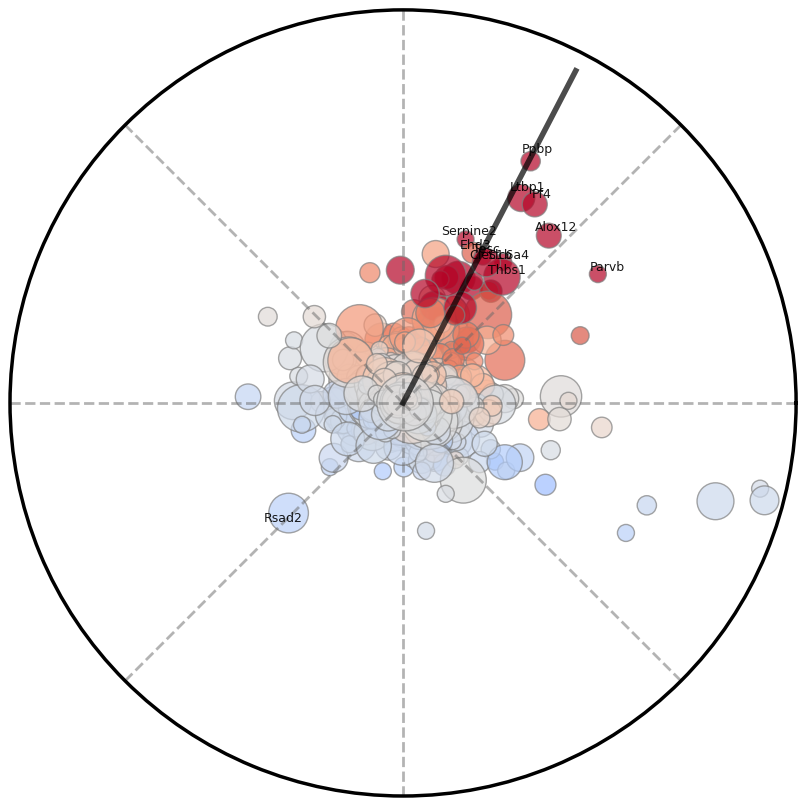

Figure saved to: ./figures/larry/polar_gene_trajectory_c.png


In [22]:
import os
# Choose which trajectory to visualize
res = results_all[0]

neighbor_indices = res["neighbor_indices"]
relative_angles  = res["relative_angles"]
magnitudes       = res["magnitudes"]
selected_genes   = res["selected_genes"]
expr_corr        = res["expr_corrs"]
vel_corr         = res["vel_corrs"]

# --- Compute base quantities ---
v_mean = analyzer.emb.V_emb[neighbor_indices].mean(axis=0)
base_angle = np.arctan2(v_mean[1], v_mean[0])
scatter_angles = base_angle + relative_angles

# ✅ Correct per-gene color: average of (J_i @ v_i) over neighbor cells
J = analyzer.jacobians[neighbor_indices, :, :]      # (Nc, G, 2)
V = analyzer.emb.V_emb[neighbor_indices]            # (Nc, 2)
vals_per_cell = np.einsum('cgd,cd->cg', J, V)       # (Nc, G)
vals = vals_per_cell.mean(axis=0)                   # (G,)
vals = vals[selected_genes]
# V_raw = analyzer.emb.V_raw[neighbor_indices][:, selected_genes]
# vals = V_raw.mean(axis=0)

cap = np.percentile(np.abs(vals), 99)
vals_clip = np.clip(vals, -cap, cap)

fit_quality = np.clip(expr_corr + vel_corr, 0, np.percentile(expr_corr + vel_corr, 99))
sizes = 1500 * (fit_quality / fit_quality.max() + 0.1)

# --- Plot base (no annotations) ---
fig, ax = plt.subplots(subplot_kw={'projection': 'polar'}, figsize=(8, 8))
ax.set_theta_zero_location('E')
ax.set_theta_direction(1)
ax.set_xticklabels([])
ax.set_yticklabels([])
ax.set_rticks([])
# Thicker and darker polar grid + axis lines
ax.xaxis.grid(True, linestyle='--', color='dimgray', alpha=0.5, lw=2)
ax.yaxis.grid(True, linestyle='--', color='dimgray', alpha=0.5, lw=2)
for spine in ax.spines.values():
    spine.set_color('black')
    spine.set_linewidth(2.5)

# Velocity direction
ax.plot([0, base_angle],
        [0, min(np.max(magnitudes), np.linalg.norm(v_mean))],
        color="black", lw=4, alpha=0.7)

# ---------------------------------------------------------------------
# Print top genes (within ±30° forward/reverse, top N by magnitude)
# ---------------------------------------------------------------------
deg2rad = np.pi / 180
angles_deg = np.degrees(relative_angles)
angles_norm = (relative_angles + 2*np.pi) % (2*np.pi)

forward_mask = (angles_norm <= 30 * deg2rad) | (angles_norm >= 2*np.pi - 30 * deg2rad)
reverse_mask = (angles_norm >= (180 - 30) * deg2rad) & (angles_norm <= (180 + 30) * deg2rad)
combined_mask = forward_mask | reverse_mask
candidate_indices = np.where(combined_mask)[0]
top_idx = candidate_indices[np.argsort(magnitudes[candidate_indices])[-12:]]

print("Top candidate genes to annotate manually:\n")
for idx in top_idx[::-1]:  # highest first
    direction = "forward" if forward_mask[idx] else "reverse"
    gname = analyzer.emb.gene_names[selected_genes[idx]]
    ang = angles_deg[idx]
    # Center angles around velocity direction for readability (-180 to 180)
    if ang > 180:
        ang -= 360
    print(f"{gname:20s} | magnitude={magnitudes[idx]:.3f} | angle={ang:7.2f}° | direction={direction}")


# ---------------------------------------------------------------------
# OPTIONAL: text annotations (comment out later if needed)
# ---------------------------------------------------------------------
annotate_idx = top_idx  # or any index list you like

for idx in annotate_idx:
    theta = scatter_angles[idx]
    r = magnitudes[idx]

    gname = analyzer.emb.gene_names[selected_genes[idx]]

    ax.text(
        theta,
        r * 1.05,              # small radial offset
        gname,
        fontsize=9,
        ha="center",
        va="center",
        color="black",
        alpha=0.9,
        clip_on=True,
    )

# Scatter points
sc = ax.scatter(
    scatter_angles, magnitudes,
    s=sizes, c=vals_clip,
    cmap='coolwarm', vmin=-cap, vmax=cap,
    alpha=0.7, edgecolors="grey"
)

save_dir = "./figures/larry"
os.makedirs(save_dir, exist_ok=True)

save_path = os.path.join(save_dir, "polar_gene_trajectory_c.png")

plt.tight_layout(pad=0.5)
plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Figure saved to: {save_path}")


Top candidate genes to annotate manually:

Ermap                | magnitude=0.330 | angle= -21.84° | direction=forward
Beta-s               | magnitude=0.283 | angle=  -9.04° | direction=forward
Ank1                 | magnitude=0.271 | angle= -20.78° | direction=forward
Klf1                 | magnitude=0.190 | angle= -27.16° | direction=forward
Cda                  | magnitude=0.159 | angle=   0.61° | direction=forward
Car2                 | magnitude=0.125 | angle=  11.05° | direction=forward
Rsad2                | magnitude=0.123 | angle= 169.62° | direction=reverse
Snca                 | magnitude=0.122 | angle= -12.76° | direction=forward
Cpox                 | magnitude=0.119 | angle= -12.01° | direction=forward
Parvb                | magnitude=0.095 | angle=   0.30° | direction=forward
Sptb                 | magnitude=0.093 | angle= -21.23° | direction=forward
Gmpr                 | magnitude=0.089 | angle=  27.55° | direction=forward


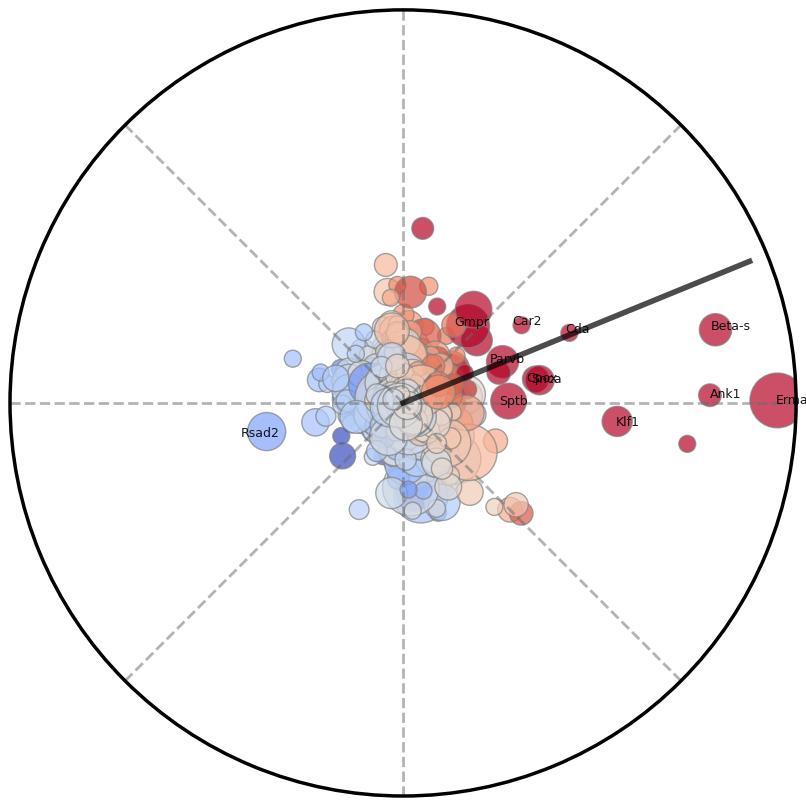

Figure saved to: ./figures/larry/polar_gene_trajectory_d.png


In [28]:
res = results_all[1]

neighbor_indices = res["neighbor_indices"]
relative_angles  = res["relative_angles"]
magnitudes       = res["magnitudes"]
selected_genes   = res["selected_genes"]
expr_corr        = res["expr_corrs"]
vel_corr         = res["vel_corrs"]

# --- Compute base quantities ---
v_mean = analyzer.emb.V_emb[neighbor_indices].mean(axis=0)
base_angle = np.arctan2(v_mean[1], v_mean[0])
scatter_angles = base_angle + relative_angles

# ✅ Correct per-gene color: average of (J_i @ v_i) over neighbor cells
J = analyzer.jacobians[neighbor_indices, :, :]      # (Nc, G, 2)
V = analyzer.emb.V_emb[neighbor_indices]            # (Nc, 2)
vals_per_cell = np.einsum('cgd,cd->cg', J, V)       # (Nc, G)
vals = vals_per_cell.mean(axis=0)                   # (G,)
vals = vals[selected_genes]
# V_raw = analyzer.emb.V_raw[neighbor_indices][:, selected_genes]
# vals = V_raw.mean(axis=0)

cap = np.percentile(np.abs(vals), 99)
vals_clip = np.clip(vals, -cap, cap)

fit_quality = np.clip(expr_corr + vel_corr, 0, np.percentile(expr_corr + vel_corr, 99))
sizes = 1500 * (fit_quality / fit_quality.max() + 0.1)

# --- Plot base (no annotations) ---
fig, ax = plt.subplots(subplot_kw={'projection': 'polar'}, figsize=(8, 8))
ax.set_theta_zero_location('E')
ax.set_theta_direction(1)
ax.set_xticklabels([])
ax.set_yticklabels([])
ax.set_rticks([])
# Thicker and darker polar grid + axis lines
ax.xaxis.grid(True, linestyle='--', color='dimgray', alpha=0.5, lw=2)
ax.yaxis.grid(True, linestyle='--', color='dimgray', alpha=0.5, lw=2)
for spine in ax.spines.values():
    spine.set_color('black')
    spine.set_linewidth(2.5)

# Velocity direction
ax.plot([0, base_angle],
        [0, min(np.max(magnitudes), np.linalg.norm(v_mean))],
        color="black", lw=4, alpha=0.7)

# ---------------------------------------------------------------------
# Print top genes (within ±30° forward/reverse, top N by magnitude)
# ---------------------------------------------------------------------
deg2rad = np.pi / 180
angles_deg = np.degrees(relative_angles)
angles_norm = (relative_angles + 2*np.pi) % (2*np.pi)

forward_mask = (angles_norm <= 30 * deg2rad) | (angles_norm >= 2*np.pi - 30 * deg2rad)
reverse_mask = (angles_norm >= (180 - 30) * deg2rad) & (angles_norm <= (180 + 30) * deg2rad)
combined_mask = forward_mask | reverse_mask
candidate_indices = np.where(combined_mask)[0]
top_idx = candidate_indices[np.argsort(magnitudes[candidate_indices])[-12:]]

print("Top candidate genes to annotate manually:\n")
for idx in top_idx[::-1]:  # highest first
    direction = "forward" if forward_mask[idx] else "reverse"
    gname = analyzer.emb.gene_names[selected_genes[idx]]
    ang = angles_deg[idx]
    # Center angles around velocity direction for readability (-180 to 180)
    if ang > 180:
        ang -= 360
    print(f"{gname:20s} | magnitude={magnitudes[idx]:.3f} | angle={ang:7.2f}° | direction={direction}")


# ---------------------------------------------------------------------
# OPTIONAL: text annotations (comment out later if needed)
# ---------------------------------------------------------------------
annotate_idx = top_idx  # or any index list you like

for idx in annotate_idx:
    theta = scatter_angles[idx]
    r = magnitudes[idx]

    gname = analyzer.emb.gene_names[selected_genes[idx]]

    ax.text(
        theta,
        r * 1.05,              # small radial offset
        gname,
        fontsize=9,
        ha="center",
        va="center",
        color="black",
        alpha=0.9,
        clip_on=True,
    )

# Scatter points
sc = ax.scatter(
    scatter_angles, magnitudes,
    s=sizes, c=vals_clip,
    cmap='coolwarm', vmin=-cap, vmax=cap,
    alpha=0.7, edgecolors="grey"
)

save_dir = "./figures/larry"
os.makedirs(save_dir, exist_ok=True)

save_path = os.path.join(save_dir, "polar_gene_trajectory_d.png")

plt.tight_layout(pad=0.5)
plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Figure saved to: {save_path}")


Top candidate genes to annotate manually:

Tpsb2                | magnitude=0.249 | angle=  -2.98° | direction=forward
Ddc                  | magnitude=0.210 | angle=   1.00° | direction=forward
Car8                 | magnitude=0.170 | angle=   2.03° | direction=forward
Gnai1                | magnitude=0.157 | angle=  -0.33° | direction=forward
Tph1                 | magnitude=0.157 | angle=  19.97° | direction=forward
Dnahc7a              | magnitude=0.147 | angle=  -3.16° | direction=forward
Avil                 | magnitude=0.143 | angle= -16.11° | direction=forward
Cobl                 | magnitude=0.137 | angle= -27.75° | direction=forward
Maob                 | magnitude=0.131 | angle=  -8.38° | direction=forward
Rsad2                | magnitude=0.126 | angle=-175.46° | direction=reverse
Vegfc                | magnitude=0.121 | angle=   5.25° | direction=forward
Kit                  | magnitude=0.117 | angle=   9.07° | direction=forward


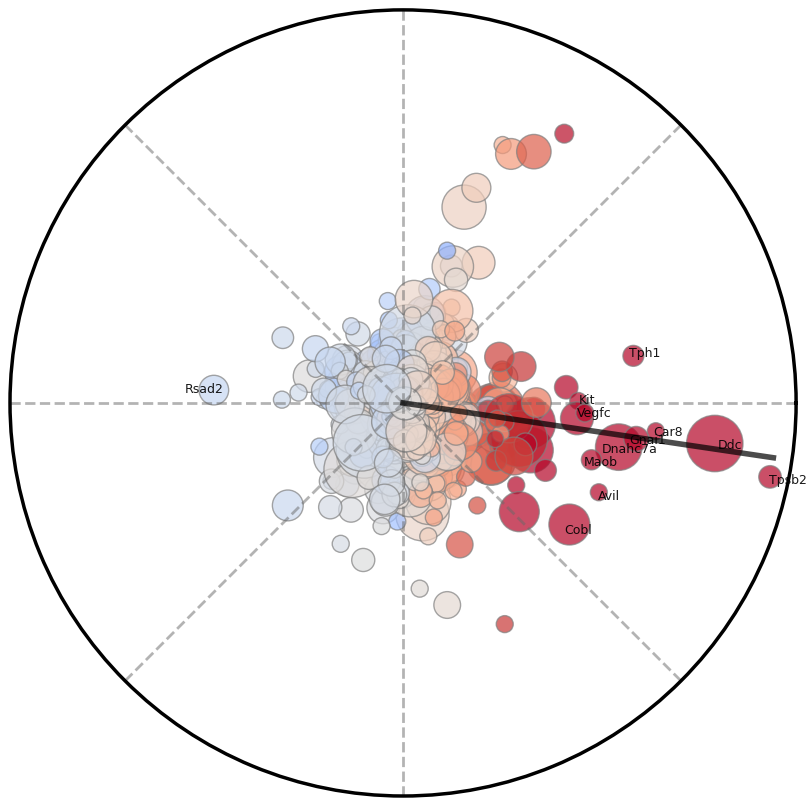

Figure saved to: ./figures/larry/polar_gene_trajectory_e.png


In [33]:
res = results_all[2]

neighbor_indices = res["neighbor_indices"]
relative_angles  = res["relative_angles"]
magnitudes       = res["magnitudes"]
selected_genes   = res["selected_genes"]
expr_corr        = res["expr_corrs"]
vel_corr         = res["vel_corrs"]

# --- Compute base quantities ---
v_mean = analyzer.emb.V_emb[neighbor_indices].mean(axis=0)
base_angle = np.arctan2(v_mean[1], v_mean[0])
scatter_angles = base_angle + relative_angles

# ✅ Correct per-gene color: average of (J_i @ v_i) over neighbor cells
J = analyzer.jacobians[neighbor_indices, :, :]      # (Nc, G, 2)
V = analyzer.emb.V_emb[neighbor_indices]            # (Nc, 2)
vals_per_cell = np.einsum('cgd,cd->cg', J, V)       # (Nc, G)
vals = vals_per_cell.mean(axis=0)                   # (G,)
vals = vals[selected_genes]
# V_raw = analyzer.emb.V_raw[neighbor_indices][:, selected_genes]
# vals = V_raw.mean(axis=0)

cap = np.percentile(np.abs(vals), 99)
vals_clip = np.clip(vals, -cap, cap)

fit_quality = np.clip(expr_corr + vel_corr, 0, np.percentile(expr_corr + vel_corr, 99))
sizes = 1500 * (fit_quality / fit_quality.max() + 0.1)

# --- Plot base (no annotations) ---
fig, ax = plt.subplots(subplot_kw={'projection': 'polar'}, figsize=(8, 8))
ax.set_theta_zero_location('E')
ax.set_theta_direction(1)
ax.set_xticklabels([])
ax.set_yticklabels([])
ax.set_rticks([])
# Thicker and darker polar grid + axis lines
ax.xaxis.grid(True, linestyle='--', color='dimgray', alpha=0.5, lw=2)
ax.yaxis.grid(True, linestyle='--', color='dimgray', alpha=0.5, lw=2)
for spine in ax.spines.values():
    spine.set_color('black')
    spine.set_linewidth(2.5)

# Velocity direction
ax.plot([0, base_angle],
        [0, min(np.max(magnitudes), np.linalg.norm(v_mean))],
        color="black", lw=4, alpha=0.7)

# ---------------------------------------------------------------------
# Print top genes (within ±30° forward/reverse, top N by magnitude)
# ---------------------------------------------------------------------
deg2rad = np.pi / 180
angles_deg = np.degrees(relative_angles)
angles_norm = (relative_angles + 2*np.pi) % (2*np.pi)

forward_mask = (angles_norm <= 30 * deg2rad) | (angles_norm >= 2*np.pi - 30 * deg2rad)
reverse_mask = (angles_norm >= (180 - 30) * deg2rad) & (angles_norm <= (180 + 30) * deg2rad)
combined_mask = forward_mask | reverse_mask
candidate_indices = np.where(combined_mask)[0]
top_idx = candidate_indices[np.argsort(magnitudes[candidate_indices])[-12:]]

print("Top candidate genes to annotate manually:\n")
for idx in top_idx[::-1]:  # highest first
    direction = "forward" if forward_mask[idx] else "reverse"
    gname = analyzer.emb.gene_names[selected_genes[idx]]
    ang = angles_deg[idx]
    # Center angles around velocity direction for readability (-180 to 180)
    if ang > 180:
        ang -= 360
    print(f"{gname:20s} | magnitude={magnitudes[idx]:.3f} | angle={ang:7.2f}° | direction={direction}")


# ---------------------------------------------------------------------
# OPTIONAL: text annotations (comment out later if needed)
# ---------------------------------------------------------------------
annotate_idx = top_idx  # or any index list you like

for idx in annotate_idx:
    theta = scatter_angles[idx]
    r = magnitudes[idx]

    gname = analyzer.emb.gene_names[selected_genes[idx]]

    ax.text(
        theta,
        r * 1.05,              # small radial offset
        gname,
        fontsize=9,
        ha="center",
        va="center",
        color="black",
        alpha=0.9,
        clip_on=True,
    )

# Scatter points
sc = ax.scatter(
    scatter_angles, magnitudes,
    s=sizes, c=vals_clip,
    cmap='coolwarm', vmin=-cap, vmax=cap,
    alpha=0.7, edgecolors="grey"
)

save_dir = "./figures/larry"
os.makedirs(save_dir, exist_ok=True)

save_path = os.path.join(save_dir, "polar_gene_trajectory_e.png")

plt.tight_layout(pad=0.5)
plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Figure saved to: {save_path}")


Top candidate genes to annotate manually:

Crisp1               | magnitude=0.097 | angle=  24.45° | direction=forward
Grm6                 | magnitude=0.096 | angle=  -2.77° | direction=forward
Rsad2                | magnitude=0.095 | angle=-161.01° | direction=reverse
Dock4                | magnitude=0.094 | angle=   6.01° | direction=forward
Hgf                  | magnitude=0.094 | angle=  -3.48° | direction=forward
L1cam                | magnitude=0.092 | angle=  21.28° | direction=forward
Plxdc2               | magnitude=0.083 | angle=  -0.51° | direction=forward
Mboat1               | magnitude=0.080 | angle= -16.61° | direction=forward
Car8                 | magnitude=0.079 | angle=  20.39° | direction=forward
Mcpt8                | magnitude=0.077 | angle= -13.41° | direction=forward
Csf1                 | magnitude=0.073 | angle=  27.41° | direction=forward
Iigp1                | magnitude=0.072 | angle= 170.41° | direction=reverse


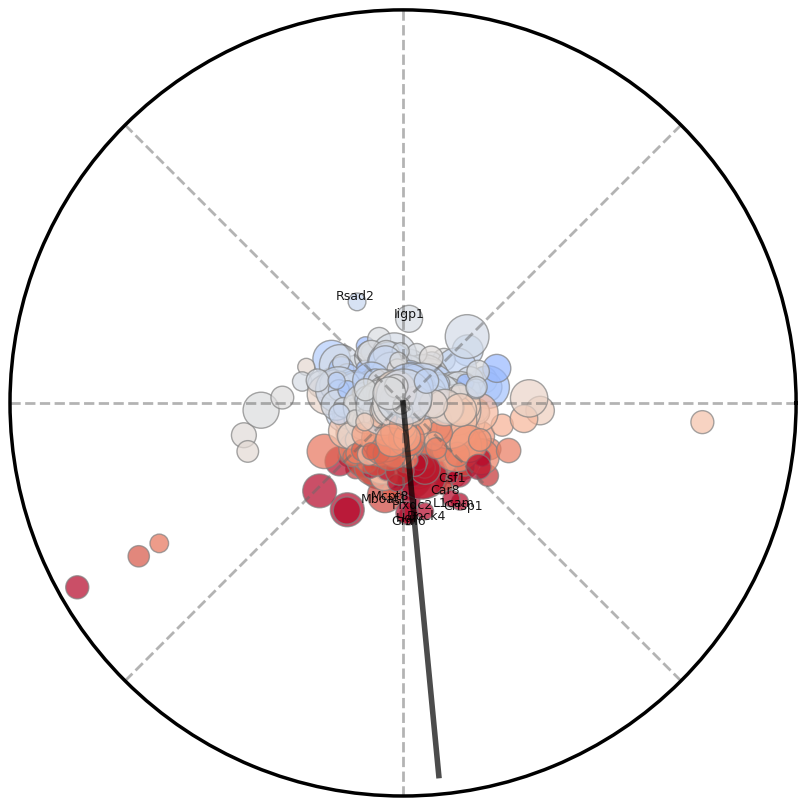

Figure saved to: ./figures/larry/polar_gene_trajectory_f.png


In [36]:
res = results_all[3]

neighbor_indices = res["neighbor_indices"]
relative_angles  = res["relative_angles"]
magnitudes       = res["magnitudes"]
selected_genes   = res["selected_genes"]
expr_corr        = res["expr_corrs"]
vel_corr         = res["vel_corrs"]

# --- Compute base quantities ---
v_mean = analyzer.emb.V_emb[neighbor_indices].mean(axis=0)
base_angle = np.arctan2(v_mean[1], v_mean[0])
scatter_angles = base_angle + relative_angles

# ✅ Correct per-gene color: average of (J_i @ v_i) over neighbor cells
J = analyzer.jacobians[neighbor_indices, :, :]      # (Nc, G, 2)
V = analyzer.emb.V_emb[neighbor_indices]            # (Nc, 2)
vals_per_cell = np.einsum('cgd,cd->cg', J, V)       # (Nc, G)
vals = vals_per_cell.mean(axis=0)                   # (G,)
vals = vals[selected_genes]
# V_raw = analyzer.emb.V_raw[neighbor_indices][:, selected_genes]
# vals = V_raw.mean(axis=0)

cap = np.percentile(np.abs(vals), 99)
vals_clip = np.clip(vals, -cap, cap)

fit_quality = np.clip(expr_corr + vel_corr, 0, np.percentile(expr_corr + vel_corr, 99))
sizes = 1500 * (fit_quality / fit_quality.max() + 0.1)

# --- Plot base (no annotations) ---
fig, ax = plt.subplots(subplot_kw={'projection': 'polar'}, figsize=(8, 8))
ax.set_theta_zero_location('E')
ax.set_theta_direction(1)
ax.set_xticklabels([])
ax.set_yticklabels([])
ax.set_rticks([])
# Thicker and darker polar grid + axis lines
ax.xaxis.grid(True, linestyle='--', color='dimgray', alpha=0.5, lw=2)
ax.yaxis.grid(True, linestyle='--', color='dimgray', alpha=0.5, lw=2)
for spine in ax.spines.values():
    spine.set_color('black')
    spine.set_linewidth(2.5)

# Velocity direction
ax.plot([0, base_angle],
        [0, min(np.max(magnitudes), np.linalg.norm(v_mean))],
        color="black", lw=4, alpha=0.7)

# ---------------------------------------------------------------------
# Print top genes (within ±30° forward/reverse, top N by magnitude)
# ---------------------------------------------------------------------
deg2rad = np.pi / 180
angles_deg = np.degrees(relative_angles)
angles_norm = (relative_angles + 2*np.pi) % (2*np.pi)

forward_mask = (angles_norm <= 30 * deg2rad) | (angles_norm >= 2*np.pi - 30 * deg2rad)
reverse_mask = (angles_norm >= (180 - 30) * deg2rad) & (angles_norm <= (180 + 30) * deg2rad)
combined_mask = forward_mask | reverse_mask
candidate_indices = np.where(combined_mask)[0]
top_idx = candidate_indices[np.argsort(magnitudes[candidate_indices])[-12:]]

print("Top candidate genes to annotate manually:\n")
for idx in top_idx[::-1]:  # highest first
    direction = "forward" if forward_mask[idx] else "reverse"
    gname = analyzer.emb.gene_names[selected_genes[idx]]
    ang = angles_deg[idx]
    # Center angles around velocity direction for readability (-180 to 180)
    if ang > 180:
        ang -= 360
    print(f"{gname:20s} | magnitude={magnitudes[idx]:.3f} | angle={ang:7.2f}° | direction={direction}")


# ---------------------------------------------------------------------
# OPTIONAL: text annotations (comment out later if needed)
# ---------------------------------------------------------------------
annotate_idx = top_idx  # or any index list you like

for idx in annotate_idx:
    theta = scatter_angles[idx]
    r = magnitudes[idx]

    gname = analyzer.emb.gene_names[selected_genes[idx]]

    ax.text(
        theta,
        r * 1.05,              # small radial offset
        gname,
        fontsize=9,
        ha="center",
        va="center",
        color="black",
        alpha=0.9,
        clip_on=True,
    )

# Scatter points
sc = ax.scatter(
    scatter_angles, magnitudes,
    s=sizes, c=vals_clip,
    cmap='coolwarm', vmin=-cap, vmax=cap,
    alpha=0.7, edgecolors="grey"
)

save_dir = "./figures/larry"
os.makedirs(save_dir, exist_ok=True)

save_path = os.path.join(save_dir, "polar_gene_trajectory_f.png")

plt.tight_layout(pad=0.5)
plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Figure saved to: {save_path}")

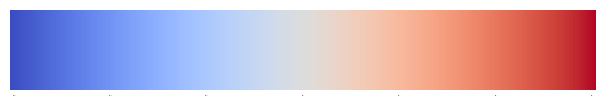

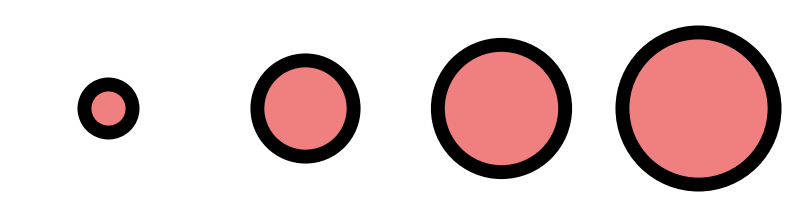

In [37]:
# ------------------------------------------------------------
# 1️⃣  Color Legend (coolwarm colormap, symmetric about 0)
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(6, 1.0))
fig.subplots_adjust(bottom=0.5)

# match the same cap values from main plot
vmin, vmax = -cap, cap
norm = plt.Normalize(vmin=vmin, vmax=vmax)
cbar = plt.colorbar(
    plt.cm.ScalarMappable(norm=norm, cmap='coolwarm'),
    cax=ax, orientation='horizontal'
)

# remove ticks & labels for a clean gradient bar
cbar.ax.tick_params(size=0, labelsize=0)
cbar.outline.set_linewidth(2)
cbar.outline.set_edgecolor("None")

plt.tight_layout(pad=0.5)
plt.show()


# Same size scaling as your main plot
min_size = 12000 * 0.1
max_size = 12000

# Create representative sizes (small → large)
sizes_ref = np.linspace(min_size, max_size, 4)

# Horizontal layout of circles
fig, ax = plt.subplots(figsize=(8, 4))
ax.set_aspect("equal")

# x positions for the circles
x_positions = np.arange(len(sizes_ref))

for x, s in zip(x_positions, sizes_ref):
    ax.scatter(x, 0, s=s, color="lightcoral", alpha=1, edgecolor="black", lw=10)

# Remove all axes and ticks
ax.set_xlim(-0.5, len(sizes_ref) - 0.5)
ax.set_ylim(-0.5, 0.5)
ax.axis("off")

plt.tight_layout(pad=0.5)
plt.show()



=== Path 1 ===
[Select] Using top 5 forward-aligned genes.


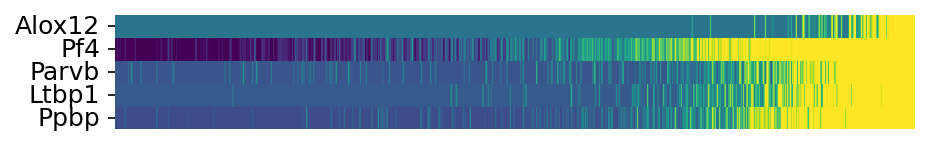


=== Path 2 ===
[Select] Using top 5 forward-aligned genes.


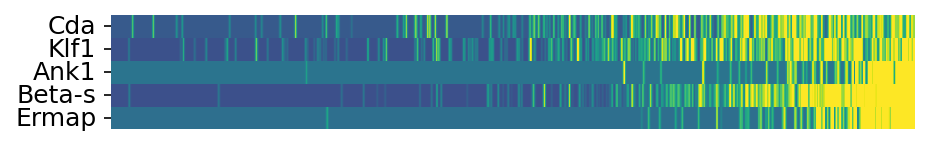


=== Path 3 ===
[Select] Using top 5 forward-aligned genes.


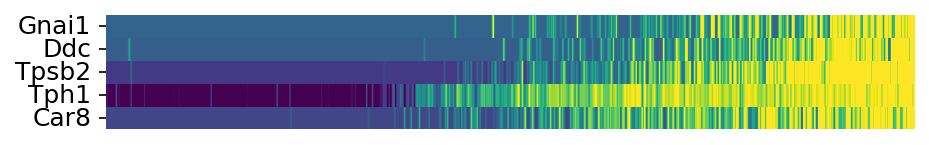


=== Path 4 ===
[Select] Using top 5 forward-aligned genes.


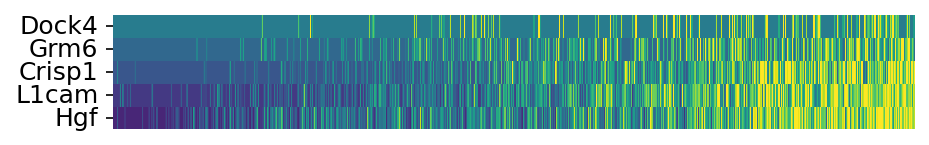

In [39]:
from scipy.ndimage import gaussian_filter1d
from scipy.cluster.hierarchy import linkage, leaves_list

def plot_path_expression_from_results(analyzer, res,
                                      top_n=10,
                                      sigma=15,
                                      cmap="mako",
                                      figsize=(10,2)):
    """
    Plot smoothed, clustered expression heatmap for the top N forward-aligned genes.
    Uses precomputed results_all entry to save time.
    """
    neighbor_indices = res["neighbor_indices"]
    relative_angles  = res["relative_angles"]
    magnitudes       = res["magnitudes"]
    selected_genes   = res["selected_genes"]

    # --- Select top N forward-aligned genes (±30°) ---
    deg2rad = np.pi / 180
    angles_norm = (relative_angles + 2*np.pi) % (2*np.pi)
    forward_mask = (angles_norm <= 30 * deg2rad) | (angles_norm >= 2*np.pi - 30 * deg2rad)
    forward_idx = np.where(forward_mask)[0]

    if len(forward_idx) == 0:
        print("[Skip] No forward-aligned genes found.")
        return

    top_idx = forward_idx[np.argsort(magnitudes[forward_idx])[-top_n:]]
    genes = np.array(analyzer.emb.gene_names)[selected_genes[top_idx]]

    print(f"[Select] Using top {len(genes)} forward-aligned genes.")

    # --- Get expression matrix ---
    X = analyzer.emb.X_raw[neighbor_indices]
    X = X[:, selected_genes[top_idx]]

    # --- Project cells onto path & sort ---
    path_coords = np.array(res["trajectory"])
    X_emb = analyzer.emb.X_emb[neighbor_indices]
    dist_to_path = np.linalg.norm(X_emb[:, None, :] - path_coords[None, :, :], axis=2)
    path_position = np.argmin(dist_to_path, axis=1)
    sort_order = np.argsort(path_position)
    X_sorted = X[sort_order]

    # --- Normalize and smooth ---
    X_norm = (X_sorted - X_sorted.mean(axis=0)) / (X_sorted.std(axis=0) + 1e-8)
    X_smooth = gaussian_filter1d(X_norm, sigma=sigma, axis=0, mode="nearest")

    # --- Cluster genes by expression pattern ---
    if X_smooth.shape[1] > 1:
        gene_link = linkage(X_smooth.T, method="average", metric="correlation")
        gene_order = leaves_list(gene_link)
    else:
        gene_order = np.arange(X_smooth.shape[1])

    X_clustered = X_smooth[:, gene_order]
    genes_ordered = np.array(genes)[gene_order]

    # --- Plot heatmap with gene names ---
    plt.figure(figsize=figsize, facecolor="white", dpi=150)
    sns.heatmap(
        X_clustered.T,
        cmap=cmap,
        center=0,
        vmin=-1, vmax=1,
        cbar=False,
        xticklabels=False,
        yticklabels=genes_ordered,
        linewidths=0,
        linecolor=None
    )
    plt.yticks(fontsize=12)
    plt.xticks([])
    plt.box(False)
    plt.tight_layout(pad=0)
    plt.show()


# ------------------------------------------------------------------
# Plot all four trajectories using saved results_all
# ------------------------------------------------------------------
for i, res in enumerate(results_all[:4], 1):
    print(f"\n=== Path {i} ===")
    plot_path_expression_from_results(
        analyzer, res,
        top_n=5,
        sigma=2,
        cmap="viridis",
        figsize=(6,0.8)
    )


<Figure size 900x800 with 0 Axes>

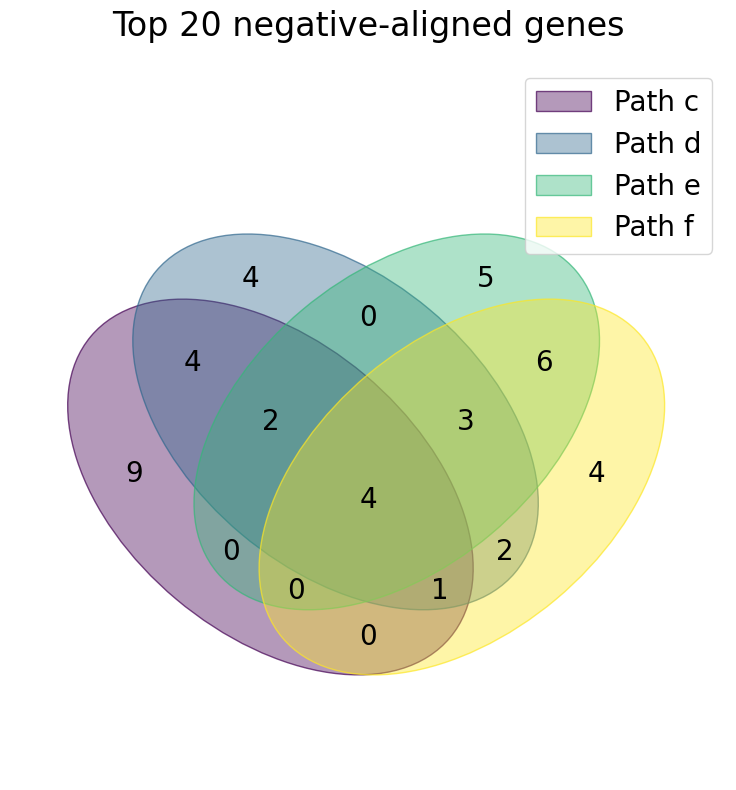

In [53]:
import numpy as np

deg = np.pi / 180
anti_width = 30 * deg

gene_names = analyzer.emb.gene_names

topN = 20
neg_gene_sets = []

for i in range(4):
    res = results_all[i]

    angles = (res["relative_angles"] + 2*np.pi) % (2*np.pi)
    mags   = res["magnitudes"]
    sel    = res["selected_genes"]

    # anti-parallel mask
    anti_mask = (
        (angles >= np.pi - anti_width) &
        (angles <= np.pi + anti_width)
    )

    idxs = np.where(anti_mask)[0]

    # top-N by magnitude
    top_idxs = idxs[np.argsort(mags[idxs])[-topN:]]

    genes = gene_names[sel[top_idxs]]
    neg_gene_sets.append(set(genes))

from venn import venn
import matplotlib.pyplot as plt

gene_sets = {
    "Path c": neg_gene_sets[0],
    "Path d": neg_gene_sets[1],
    "Path e": neg_gene_sets[2],
    "Path f": neg_gene_sets[3],
}

plt.figure(figsize=(9, 8))

ax = venn(
    gene_sets,
    fontsize=20,         
)

plt.title(
    "Top 20 negative-aligned genes",
    fontsize=24,
    pad=20
)

plt.tight_layout()
plt.show()


<Figure size 900x800 with 0 Axes>

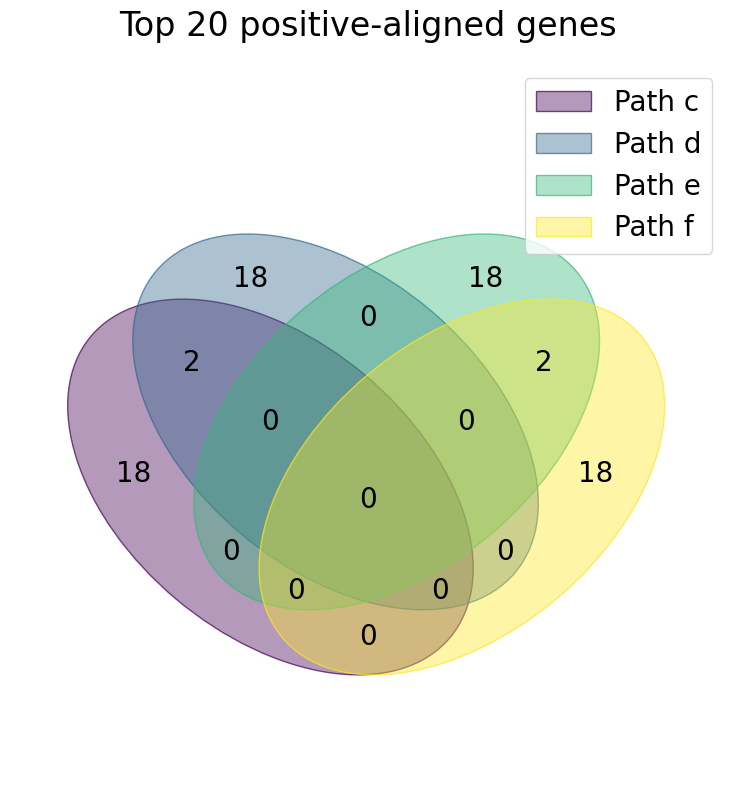

In [54]:
import numpy as np
import matplotlib.pyplot as plt
from venn import venn

deg = np.pi / 180
pos_width = 30 * deg   # ±30° around 0

gene_names = analyzer.emb.gene_names
topN = 20
pos_gene_sets = []

for i in range(4):
    res = results_all[i]

    angles = (res["relative_angles"] + 2*np.pi) % (2*np.pi)
    mags   = res["magnitudes"]
    sel    = res["selected_genes"]

    # positive-aligned (parallel) mask
    pos_mask = (
        (angles <= pos_width) |
        (angles >= 2*np.pi - pos_width)
    )

    idxs = np.where(pos_mask)[0]

    # top-N by magnitude
    top_idxs = idxs[np.argsort(mags[idxs])[-topN:]]

    genes = gene_names[sel[top_idxs]]
    pos_gene_sets.append(set(genes))

# ------------------------------------------------------------
# 4-set Venn diagram
# ------------------------------------------------------------
gene_sets = {
    "Path c": pos_gene_sets[0],
    "Path d": pos_gene_sets[1],
    "Path e": pos_gene_sets[2],
    "Path f": pos_gene_sets[3],
}

plt.figure(figsize=(9, 8))

ax = venn(
    gene_sets,
    fontsize=20,         
)

plt.title(
    "Top 20 positive-aligned genes",
    fontsize=24,
    pad=20
)

plt.tight_layout()
plt.show()

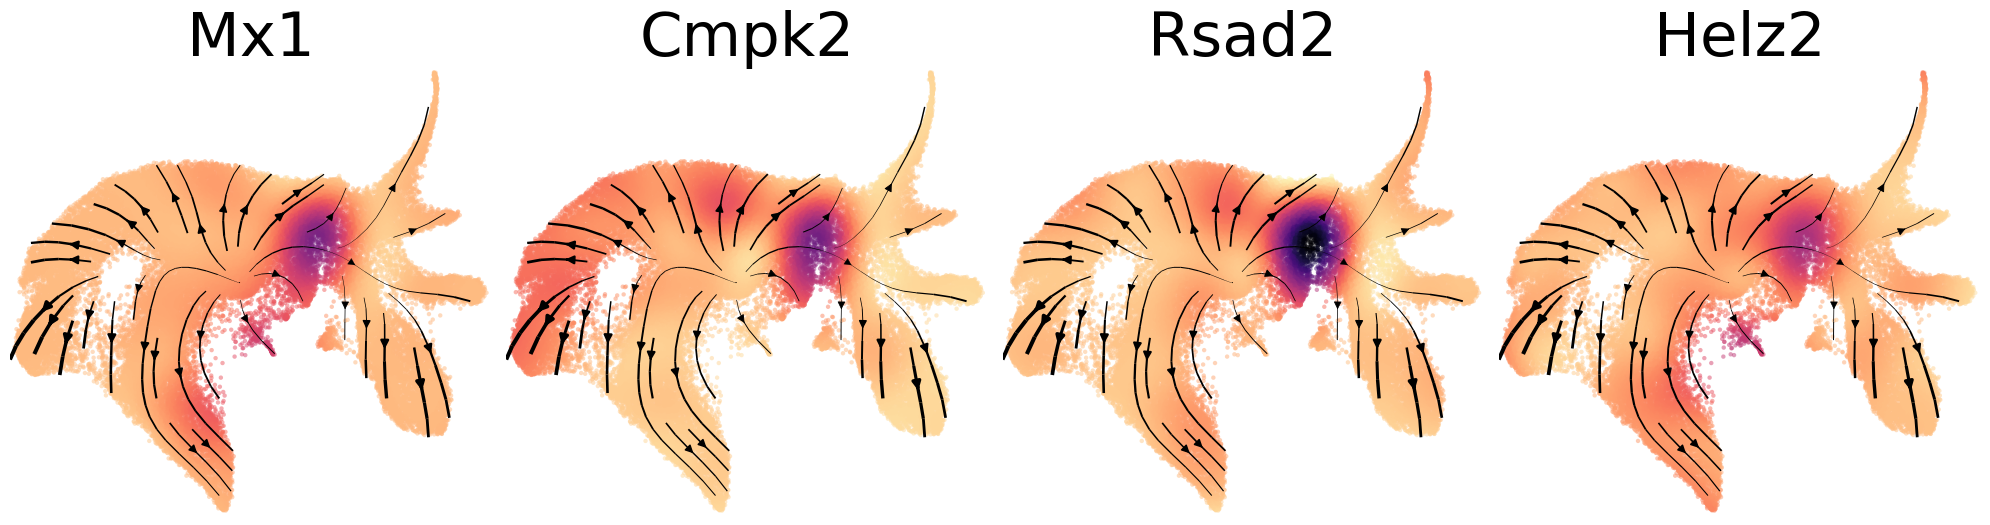

In [58]:
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Shared negative-aligned genes (example core set)
# ------------------------------------------------------------
shared_genes = (
    neg_gene_sets[0]
    & neg_gene_sets[1]
    & neg_gene_sets[2]
    & neg_gene_sets[3]
)
genes_to_plot = list(shared_genes)

# ------------------------------------------------------------
# Smoothed expression on manifold
# ------------------------------------------------------------
pred_expr = emb.tps_gene.predict(emb.X_emb)  # (n_cells, n_genes)
gene_names = (
    emb.tps_gene.gene_names
    if hasattr(emb.tps_gene, "gene_names")
    else adata.var_names.to_numpy()
)

# shared color scale
all_expr = []
for gene in genes_to_plot:
    gidx = np.where(gene_names == gene)[0][0]
    all_expr.append(pred_expr[:, gidx])

all_expr = np.concatenate(all_expr)
vmin, vmax = np.min(all_expr), np.max(all_expr)

# ------------------------------------------------------------
# Plot: 1×4 panels
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharex=True, sharey=True)

for ax, gene in zip(axes, genes_to_plot):
    gidx = np.where(gene_names == gene)[0][0]
    expr = pred_expr[:, gidx]

    plot_velocity_streamplot(
        X_2d=emb.X_emb,
        tps_vf=emb.tps_vf,        # velocity field (for streamlines)
        scatter_color=expr,       # smoothed expression
        cmap="magma_r",
        vmin=vmin,
        vmax=vmax,
        scatter_size=10,
        scatter_alpha=0.5,
        stream_density=0.8,
        streamline_thickness=3.0,
        arrowsize=1.2,
        show_axes=False,
        show_colorbar=False,
        ax=ax,
    )

    ax.set_title(gene, fontsize=44)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_frame_on(False)

plt.tight_layout()
plt.show()

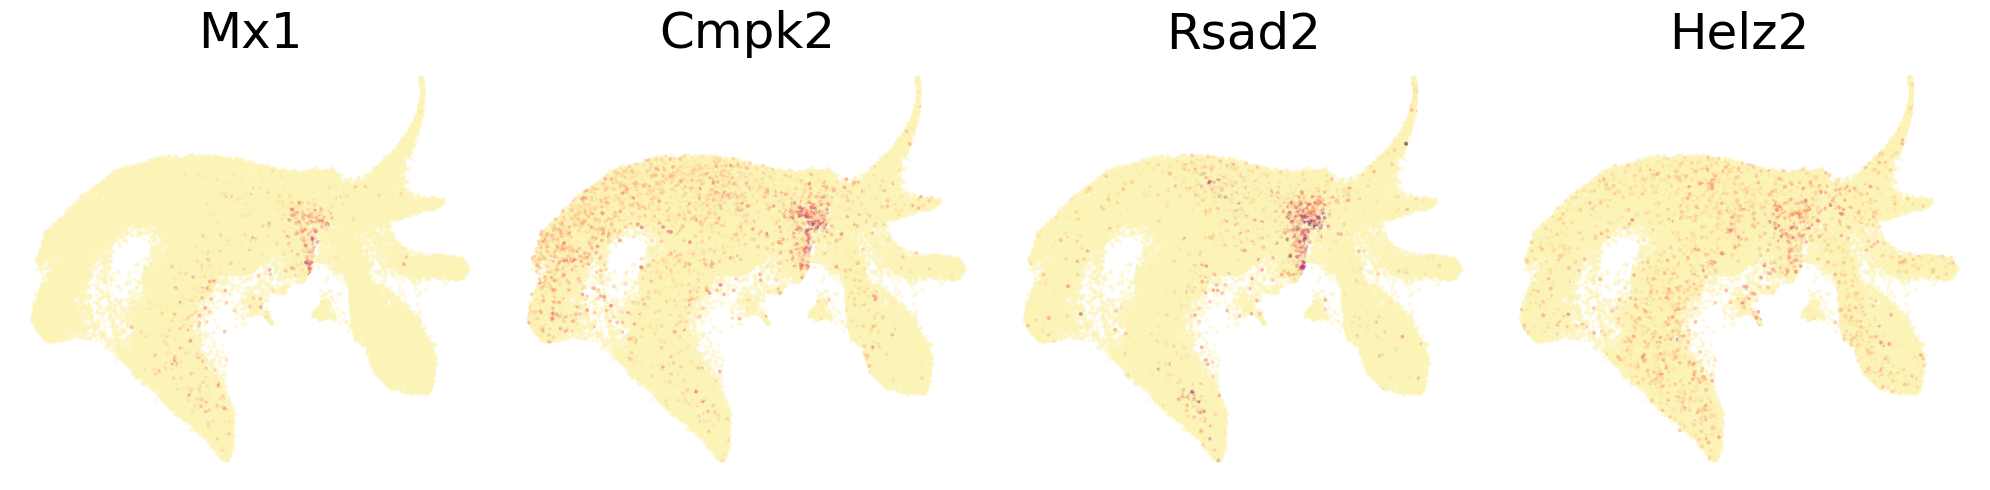

In [61]:
import matplotlib.colors as colors

# --------------------------------------------------------------------------
# Get raw expression
# --------------------------------------------------------------------------
gene_names = adata.var_names.to_numpy()

X_raw = adata.X
if hasattr(X_raw, "toarray"):
    X_raw = X_raw.toarray()

# --------------------------------------------------------------------------
# Shared color scale (across the 4 genes)
# --------------------------------------------------------------------------
all_expr = []
for gene in genes_to_plot:
    idx = np.where(gene_names == gene)[0][0]
    all_expr.append(X_raw[:, idx])

all_expr = np.concatenate(all_expr)
vmin, vmax = np.min(all_expr), np.max(all_expr)

def truncate_colormap(cmap, minval=0.15, maxval=1.0, n=256):
    return colors.LinearSegmentedColormap.from_list(
        "trunc_" + cmap.name,
        cmap(np.linspace(minval, maxval, n))
    )

cmap_dark = truncate_colormap(cm.magma_r, minval=0.02)

# --------------------------------------------------------------------------
# Plot: raw expression only
# --------------------------------------------------------------------------
fig, axes = plt.subplots(
    1, len(genes_to_plot),
    figsize=(5 * len(genes_to_plot), 5),
    sharex=True, sharey=True
)

if len(genes_to_plot) == 1:
    axes = [axes]

last_scatter = None

for ax, gene in zip(axes, genes_to_plot):
    idx = np.where(gene_names == gene)[0][0]

    sc = ax.scatter(
        emb.X_emb[:, 0],
        emb.X_emb[:, 1],
        c=X_raw[:, idx],
        cmap=cmap_dark,
        s=8,
        alpha=0.5,
        vmin=vmin,
        vmax=vmax,
        linewidths=0
    )

    ax.set_title(gene, fontsize=36)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_frame_on(False)

    last_scatter = sc

plt.tight_layout()
plt.show()